# Quantum Fit Check

**Is this problem worth running on today's quantum computers, and what would it cost?**

**Who it is for:** an operations or analytics lead (a hospital bed manager, a logistics planner) who
has been told quantum might help and has to decide whether to spend time and budget finding out.

Give the tool a problem. It builds the quantum circuit in Qiskit, compiles it for a real IBM device,
and reports the qubits needed, the chance a shot finishes without an error, the QPU seconds, the price
on each IBM plan, and how long a classical computer takes on the same problem. Then it tests its own
estimates against a noisy simulator and real hardware.

The tool never claims quantum wins. A "worth a hardware test" verdict only means the circuit can run
cleanly enough to measure.

Everything up to section 7 runs without an IBM key and uses no QPU time.

## 0. Setup

In [1]:
import os, subprocess, sys

REPO = "https://github.com/Illia-Shyn/Quantum_Hackathon_Noble_Raptors.git"
if not os.path.isdir("fitcheck"):
    if os.path.isdir("../fitcheck"):          # opened from the repository's notebooks/ folder
        os.chdir("..")
    else:                                     # fresh Colab session
        subprocess.run(["git", "clone", "-q", REPO, "quantum_fit_check"], check=True)
        os.chdir("quantum_fit_check")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, os.getcwd())

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import qiskit
from IPython.display import Markdown, display

import fitcheck as fc

backend = fc.local_backend("fez")             # local copy of ibm_fez: no key, no QPU time
print("Qiskit", qiskit.__version__)
print(fc.device_summary(backend))

Qiskit 2.6.2
{'backend': 'fake_fez', 'num_qubits': 156, 'two_qubit_gate': 'cz', 'median_two_qubit_error': 0.0039033828523107883, 'median_sx_error': 0.00022868757107977525, 'median_readout_error': 0.007568359375}


## 1. Ask in plain language

Type a task as a sentence. If a Gemini key is set (`GEMINI_API_KEY` in Colab Secrets or the
environment), a language model turns the sentence into a problem type and a size. Without a key the
tool falls back to keyword matching, so this cell always runs.

The language model never produces a number in the report. It only picks the template; Qiskit does the rest.

In [2]:
request = "We need to assign 4 patients to 4 hospital beds at the lowest total cost"

spec, report = fc.check_request(request, backend)
print("How the request was understood:", spec)
display(Markdown(report.to_markdown()))

How the request was understood: {'problem_type': 'assignment', 'size': 4, 'understood': "Read as a 'assignment' task by keyword matching.", 'source': 'keywords'}


## Quantum Fit Check: Assign 4 patients to 4 beds

Give each of 4 patients one of 4 beds at the lowest total cost.

**Verdict: worth a hardware test**

**In plain words:** The circuit is small enough that roughly 46% of runs would finish without an error, for about $3.62 per job, so it is a fair experiment, not a faster way to get the answer. A classical computer solves it in 0.006 ms.

- About 46% of shots are expected to finish without an error, so a hardware run would return a usable signal.
- Fits on the device: 16 of 156 qubits, 182 two-qubit gates.
- A classical computer solved this same problem in 0.006 ms (Hungarian algorithm (exact, polynomial time)).
- A 'worth a hardware test' verdict means the circuit can run cleanly enough to measure. It never means quantum beats the classical solver.

**Problem shape: classical-shaped.** The assignment problem is solved exactly in polynomial time by the Hungarian algorithm. Quantum cannot beat an already-efficient exact method here.

| Measure | Value |
| --- | --- |
| Device | fake_fez (156 qubits) |
| Qubits needed | 16 |
| QAOA layers | 1 |
| Circuit depth after transpiling | 254 |
| Two-qubit gates | 182 |
| Circuit duration | 10.8 microseconds |
| Estimated success chance per shot | 46.29% |
| Estimated QPU time (1000 shots) | 2.26 s |
| Share of the 10 free minutes | 0.38% |
| Price, Pay-As-You-Go | $3.62 |
| Price, Flex | $2.71 |
| Price, Premium | $1.81 |
| Full QAOA search (100 such jobs), QPU time | 226 s |
| Full QAOA search, Pay-As-You-Go | $361.72 |
| Full QAOA search, fits in the 10 free minutes? | yes |
| Classical solver | Hungarian algorithm (exact, polynomial time) |
| Classical solve time (measured) | 0.006 ms |

In [3]:
# Tasks the tool cannot turn into a circuit still get a shape label and the reasoning behind it.
for text in ["Find the ground-state energy of a drug molecule",
             "Train an image classifier on 1 million photos",
             "Split a delivery network of 12 depots into two balanced regions"]:
    spec, rep = fc.check_request(text, backend)
    print(f"{text}\n  -> type: {spec['problem_type']} | shape: {rep.shape} | verdict: {rep.verdict}\n")

Find the ground-state energy of a drug molecule
  -> type: molecule_energy | shape: quantum-shaped | verdict: not sized

Train an image classifier on 1 million photos
  -> type: other | shape: classical-shaped | verdict: not sized

Split a delivery network of 12 depots into two balanced regions
  -> type: maxcut | shape: open question | verdict: worth a hardware test



## 2. The pipeline, step by step

The same five stages on one small example: Max-Cut on a 10-node network.

**Stage 1, the problem.** Split the nodes into two groups so that as many links as possible are cut.

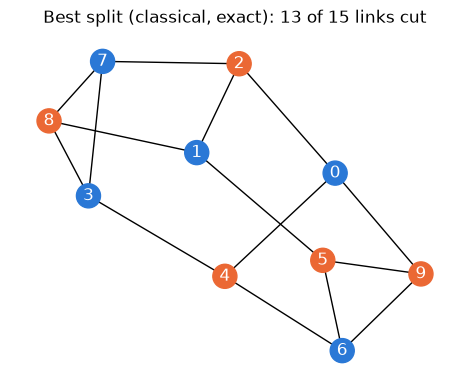

Cost Hamiltonian: 15 ZZ terms on 10 qubits


In [4]:
graph = fc.random_graph(10, degree=3, seed=7)
problem = fc.maxcut_problem(graph)
classical = fc.solve_classically(problem)
colors = ["#2a78d6" if b else "#eb6834" for b in classical["bits"]]
plt.figure(figsize=(4.5, 3.5))
nx.draw(problem.meta["graph"], pos=nx.spring_layout(problem.meta["graph"], seed=3), node_color=colors,
        with_labels=True, font_color="white")
plt.title(f"Best split (classical, exact): {classical['cut']:.0f} of {graph.number_of_edges()} links cut")
plt.show()
print("Cost Hamiltonian:", problem.hamiltonian().size, "ZZ terms on", problem.num_qubits, "qubits")

**Stage 2, the circuit.** A QAOA circuit built gate by gate from the problem's terms: one qubit per node, one `RZZ` gate per link.

Parameters: ['beta[0]', 'gamma[0]']


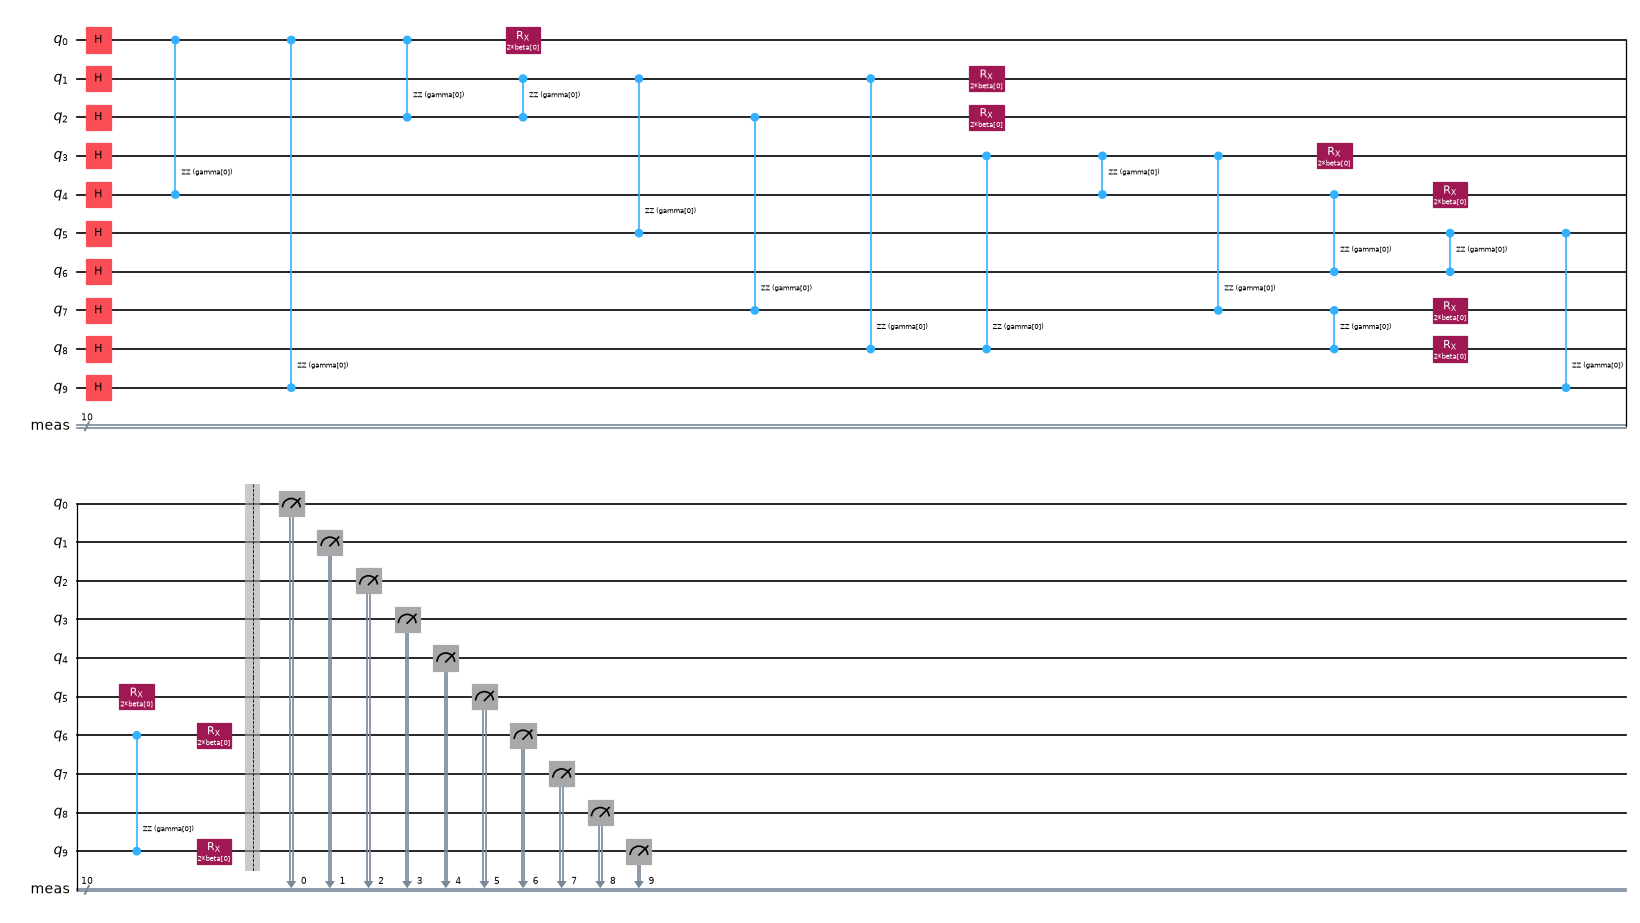

In [5]:
circuit = fc.qaoa_circuit(problem, reps=1, measure=True)
print("Parameters:", [p.name for p in circuit.parameters])
circuit.draw("mpl", fold=40, scale=0.6)

**Stage 3, transpile.** Compile for the device's own gates and wiring. Extra gates appear because the device only links neighbouring qubits.

In [6]:
isa = fc.transpile_for(backend, fc.bind_random(circuit))
metrics = fc.circuit_metrics(backend, isa)
print("Before:", dict(circuit.count_ops()))
print("After: ", metrics["gate_counts"])
print(f"Depth {metrics['depth']}, two-qubit gates {metrics['two_qubit_gates']}, "
      f"duration {metrics['duration_seconds'] * 1e6:.1f} microseconds")

Before: {'rzz': 15, 'h': 10, 'rx': 10, 'measure': 10, 'barrier': 1}
After:  {'sx': 141, 'rz': 114, 'cz': 70, 'measure': 10, 'x': 3, 'barrier': 1}
Depth 131, two-qubit gates 70, duration 6.1 microseconds


**Stages 4 and 5, estimate and verdict.**

In [7]:
report = fc.fit_check(problem, backend, reps=1, shots=1000)
display(Markdown(report.to_markdown()))
print("Where the errors come from (chance each gate type causes no error):")
for gate, value in report.success_by_gate.items():
    print(f"  {gate:8s} {value:.3f}")

## Quantum Fit Check: Max-Cut on 10 nodes

Split a network of 10 nodes and 15 links into two groups, cutting as many links as possible.

**Verdict: worth a hardware test**

**In plain words:** The circuit is small enough that roughly 74% of runs would finish without an error, for about $3.61 per job, so it is a fair experiment, not a faster way to get the answer. A classical computer solves it in 0.266 ms.

- About 74% of shots are expected to finish without an error, so a hardware run would return a usable signal.
- Fits on the device: 10 of 156 qubits, 70 two-qubit gates.
- A classical computer solved this same problem in 0.266 ms (brute force (exact)).
- A 'worth a hardware test' verdict means the circuit can run cleanly enough to measure. It never means quantum beats the classical solver.

**Problem shape: open question.** Graph partitioning is hard for classical computers in the worst case, but no quantum advantage has been proven for QAOA on it, and good classical heuristics exist.

| Measure | Value |
| --- | --- |
| Device | fake_fez (156 qubits) |
| Qubits needed | 10 |
| QAOA layers | 1 |
| Circuit depth after transpiling | 131 |
| Two-qubit gates | 70 |
| Circuit duration | 6.1 microseconds |
| Estimated success chance per shot | 74.01% |
| Estimated QPU time (1000 shots) | 2.26 s |
| Share of the 10 free minutes | 0.38% |
| Price, Pay-As-You-Go | $3.61 |
| Price, Flex | $2.71 |
| Price, Premium | $1.80 |
| Full QAOA search (100 such jobs), QPU time | 226 s |
| Full QAOA search, Pay-As-You-Go | $360.98 |
| Full QAOA search, fits in the 10 free minutes? | yes |
| Classical solver | brute force (exact) |
| Classical solve time (measured) | 0.266 ms |

Where the errors come from (chance each gate type causes no error):
  cz       0.814
  measure  0.937
  rz       1.000
  sx       0.972
  x        1.000


## 3. How far does it scale? Two problems

**Problem A, hospital bed assignment (synthetic data).** One qubit per patient-bed pair, so the qubits
grow as the square of the number of patients. The classical Hungarian algorithm solves it exactly.

In [8]:
rows = []
for n in [2, 3, 4, 5, 6, 8, 10, 12, 13]:
    r = fc.fit_check(fc.assignment_problem(fc.synthetic_costs(n)), backend)
    rows.append((n, r))
    print(f"{n:>2} patients | {r.logical_qubits:>3} qubits | 2q gates {r.metrics.get('two_qubit_gates', '-'):>6} | "
          f"success {fc.core.pct(r.success) if r.success is not None else '-':>11} | "
          f"classical {r.classical['seconds'] * 1000:.3f} ms | {r.verdict}"
          + (f" (errors must be {r.error_reduction_needed:,.1f}x lower)" if r.error_reduction_needed else ""))
print()
for row in fc.assignment_scaling((10, 100, 1000)):
    print(f"Classical: {row['patients']:>4} patients solved exactly in {row['classical_seconds'] * 1000:8.2f} ms "
          f"(QAOA would need {row['qubits_needed']:,} qubits)")

 2 patients |   4 qubits | 2q gates     10 | success      94.67% | classical 0.004 ms | worth a hardware test
 3 patients |   9 qubits | 2q gates     57 | success      77.60% | classical 0.005 ms | worth a hardware test
 4 patients |  16 qubits | 2q gates    182 | success      46.29% | classical 0.003 ms | worth a hardware test
 5 patients |  25 qubits | 2q gates    499 | success      11.59% | classical 0.004 ms | worth a hardware test


 6 patients |  36 qubits | 2q gates   1004 | success       1.13% | classical 0.004 ms | runs, but noise dominates (errors must be 1.9x lower)
 8 patients |  64 qubits | 2q gates   3611 | success under 0.01% | classical 0.005 ms | runs, but noise dominates (errors must be 7.7x lower)


10 patients | 100 qubits | 2q gates   7527 | success under 0.01% | classical 0.005 ms | runs, but noise dominates (errors must be 16.4x lower)


12 patients | 144 qubits | 2q gates  15069 | success under 0.01% | classical 0.006 ms | runs, but noise dominates (errors must be 33.7x lower)
13 patients | 169 qubits | 2q gates      - | success           - | classical 0.007 ms | does not fit

Classical:   10 patients solved exactly in     0.00 ms (QAOA would need 100 qubits)
Classical:  100 patients solved exactly in     0.06 ms (QAOA would need 10,000 qubits)
Classical: 1000 patients solved exactly in     3.03 ms (QAOA would need 1,000,000 qubits)


**Problem B, Max-Cut on growing networks.** One qubit per node, so it fits on the device for much longer, but the success chance still falls quickly.

  4 nodes | 2q gates    18 | success      92.20% | QPU 2.25 s | $3.61 pay-as-you-go | worth a hardware test
  8 nodes | 2q gates    44 | success      81.95% | QPU 2.25 s | $3.61 pay-as-you-go | worth a hardware test
 12 nodes | 2q gates    84 | success      69.23% | QPU 2.26 s | $3.61 pay-as-you-go | worth a hardware test
 16 nodes | 2q gates   118 | success      57.80% | QPU 2.26 s | $3.61 pay-as-you-go | worth a hardware test
 20 nodes | 2q gates   160 | success      43.56% | QPU 2.26 s | $3.61 pay-as-you-go | worth a hardware test
 30 nodes | 2q gates   241 | success      21.85% | QPU 2.26 s | $3.62 pay-as-you-go | worth a hardware test
 40 nodes | 2q gates   431 | success       9.48% | QPU 2.26 s | $3.62 pay-as-you-go | runs, but noise dominates (errors must be 1.0x lower)
 60 nodes | 2q gates  1023 | success       0.16% | QPU 2.27 s | $3.64 pay-as-you-go | runs, but noise dominates (errors must be 2.8x lower)
 80 nodes | 2q gates  1350 | success       0.01% | QPU 2.27 s | $3.64 pa

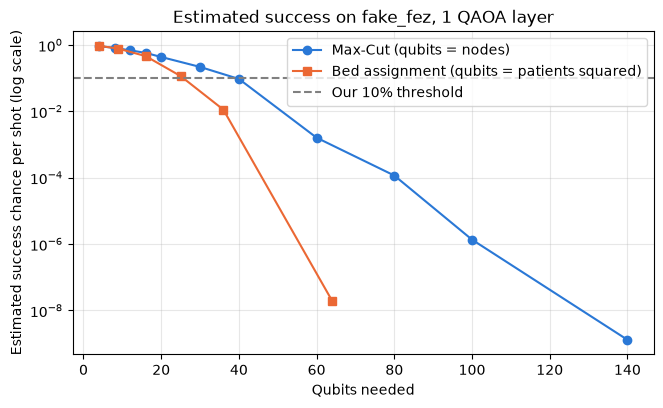

In [9]:
sizes = [4, 8, 12, 16, 20, 30, 40, 60, 80, 100, 140, 156]
maxcut_reports = [fc.fit_check(fc.maxcut_problem(fc.random_graph(n)), backend) for n in sizes]
for n, r in zip(sizes, maxcut_reports):
    if r.success is None:
        print(f"{n:>3} nodes | {r.verdict}: {r.reasons[0]}")
        continue
    print(f"{n:>3} nodes | 2q gates {r.metrics['two_qubit_gates']:>5} | success {fc.core.pct(r.success):>11} | "
          f"QPU {r.qpu_seconds:.2f} s | ${r.price['Pay-As-You-Go']:.2f} pay-as-you-go | {r.verdict}"
          + (f" (errors must be {r.error_reduction_needed:,.1f}x lower)" if r.error_reduction_needed else ""))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
fitting = [r for r in maxcut_reports if r.success is not None]
FLOOR = 1e-12                                 # smaller values are left off the chart
fitting = [r for r in fitting if r.success >= FLOOR]
ax.semilogy([r.logical_qubits for r in fitting], [r.success for r in fitting], "o-", color="#2a78d6", label="Max-Cut (qubits = nodes)")
beds_fit = [r for _, r in rows if r.success is not None and r.success >= FLOOR]
ax.semilogy([r.logical_qubits for r in beds_fit], [r.success for r in beds_fit], "s-", color="#eb6834",
            label="Bed assignment (qubits = patients squared)")
ax.axhline(fc.core.SUCCESS_THRESHOLD, color="gray", linestyle="--", label="Our 10% threshold")
ax.set_xlabel("Qubits needed"); ax.set_ylabel("Estimated success chance per shot (log scale)")
ax.set_title(f"Estimated success on {backend.name}, 1 QAOA layer"); ax.grid(alpha=0.3); ax.legend(loc="upper right")
os.makedirs("results", exist_ok=True)
fig.savefig("results/success_vs_size.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Does QAOA find the answer at all?

On a noiseless simulator, for sizes small enough to check exactly. This uses Qiskit's `StatevectorEstimator`
inside a classical optimiser loop (a hybrid workflow), then samples the best circuit.

In [10]:
small_graph = fc.maxcut_problem(fc.random_graph(8))
q = fc.solve_qaoa(small_graph, reps=2)
print(f"Max-Cut, 8 nodes, 2 layers: best cut sampled {-q['best_sampled_cost']:.0f}, optimum {-q['optimal_cost']:.0f}, "
      f"approximation ratio {q['approximation_ratio']:.2f}, {q['share_of_shots_optimal']:.0%} of shots optimal")

beds = fc.assignment_problem(fc.synthetic_costs(3))
q = fc.solve_qaoa(beds, reps=1)
print(f"Bed assignment, 3 patients, 1 layer: best cost sampled {q['best_sampled_cost']:.0f}, optimum {q['optimal_cost']:.0f}, "
      f"only {q['share_of_shots_optimal']:.1%} of shots optimal")

Max-Cut, 8 nodes, 2 layers: best cut sampled 10, optimum 10, approximation ratio 0.88, 36% of shots optimal


Bed assignment, 3 patients, 1 layer: best cost sampled 16, optimum 16, only 1.2% of shots optimal


QAOA does well on the small graph. On the assignment problem most shots break the one-bed-per-patient
rule, even with no noise, while the classical method is exact in microseconds. That matches its
"classical-shaped" label.

## 5. Testing our own estimate on a noisy simulator

A **mirror circuit** is a circuit followed by its inverse. A perfect device returns all zeros, so the
share of all-zero shots is the measured success. We compare that with our prediction for growing
problems, three random graphs per size, on a simulator built from the device's error rates. No QPU time.

In [11]:
sim_rows = fc.simulator_sweep(sizes=(4, 6, 8, 10, 12), backend=backend, reps=1, shots=2000, seeds=(1, 2, 3))
fc.save_json({"backend": backend.name, "rows": sim_rows}, "results/simulator_validation.json")
for r in sim_rows:
    print(f"{r['num_nodes']:>2} nodes | predicted {r['predicted_mean']:.3f} +/- {r['predicted_std']:.3f} | "
          f"simulated {r['simulated_mean']:.3f} +/- {r['simulated_std']:.3f}")

 4 nodes | predicted 0.877 +/- 0.005 | simulated 0.874 +/- 0.009
 6 nodes | predicted 0.802 +/- 0.007 | simulated 0.794 +/- 0.006
 8 nodes | predicted 0.703 +/- 0.019 | simulated 0.700 +/- 0.019
10 nodes | predicted 0.631 +/- 0.019 | simulated 0.625 +/- 0.011
12 nodes | predicted 0.582 +/- 0.017 | simulated 0.564 +/- 0.023


## 6. Hardware rehearsal on the local device copy

The exact code path of the real run (two Sampler jobs, error mitigation off then on), against the
local copy. It costs nothing and proves the hardware cell will work before any QPU time is spent.
On a simulator mitigation cannot help, it only adds gates; the comparison is meaningful on real hardware only.

In [12]:
rehearsal = fc.run_experiment(backend, sizes=(4, 6, 8), shots=500)
for key, run in rehearsal["runs"].items():
    print(f"mitigation {key:>3}:", [(r["num_nodes"], round(r["predicted_success"], 3), round(r["measured_success"], 3)) for r in run["rows"]])
print(f"Predicted QPU time per job on real hardware: {rehearsal['predicted_qpu_seconds_per_job']:.1f} s")

mitigation off: [(4, 0.875, 0.842), (6, 0.801, 0.776), (8, 0.721, 0.668)]
mitigation  on: [(4, 0.875, 0.793), (6, 0.801, 0.633), (8, 0.721, 0.494)]
Predicted QPU time per job on real hardware: 2.4 s


## 7. Real hardware (optional, uses QPU time)

Set `RUN_ON_HARDWARE = True` to submit. It needs `QISKIT_IBM_TOKEN` and `QISKIT_IBM_INSTANCE` in
Colab Secrets (the key icon in the sidebar) or environment variables. Never paste a key into a cell.

Two jobs of six mirror circuits, 1,000 shots each: about 8 seconds of QPU time in total by IBM's own
formula. The predictions and job IDs are saved before any result exists. If the queue is long, close
the notebook and run the collect cell later; it fetches the results by job ID.

In [13]:
RUN_ON_HARDWARE = False
PLAN_FILE = "results/hardware_run.json"

if RUN_ON_HARDWARE:
    service = fc.connect_service()
    real = fc.connect_ibm(service=service)
    print("Device:", real.name, fc.device_summary(real))
    plan, jobs = fc.submit_experiment(real, sizes=(4, 6, 8, 10, 12, 14), reps=1, shots=1000)
    plan["device_snapshot"] = fc.device_summary(real)
    fc.save_json(plan, PLAN_FILE)             # predictions and job IDs on record first
    print("Submitted:", plan["job_ids"])
else:
    print("Skipped. Nothing was submitted.")

Skipped. Nothing was submitted.


In [14]:
# Collect: run this once the jobs have finished (also works in a new session).
if os.path.exists(PLAN_FILE):
    plan = fc.load_json(PLAN_FILE)
    if "runs" not in plan and RUN_ON_HARDWARE:
        plan = fc.collect_experiment(plan, service=fc.connect_service())
        fc.save_json(plan, PLAN_FILE)
    hardware_results = plan if "runs" in plan else None
else:
    hardware_results = None
print("Hardware results available:", hardware_results is not None)
if hardware_results:
    for key, run in hardware_results["runs"].items():
        print(f"mitigation {key}: job {run['job_id']}, QPU seconds used {run['qpu_seconds_used']} "
              f"(predicted {hardware_results['predicted_qpu_seconds_per_job']:.1f})")
        for r in run["rows"]:
            print(f"   {r['num_nodes']:>2} nodes | predicted {r['predicted_success']:.3f} | "
                  f"measured {r['measured_success']:.3f} +/- {r['measured_stderr']:.3f}")

Hardware results available: False


## 8. Headline chart: predicted against measured success

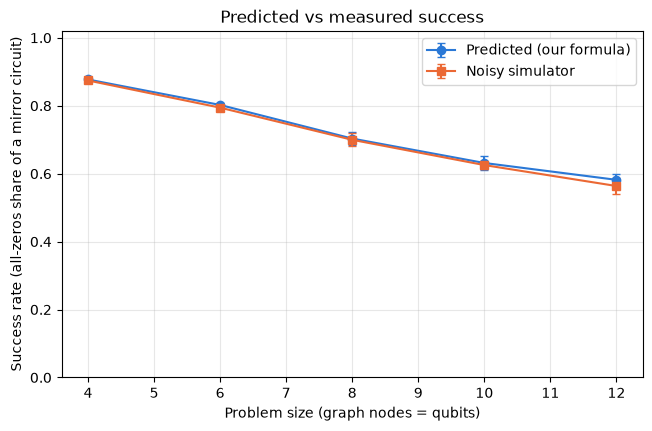

In [15]:
ax = fc.plot_validation(sim_rows, hardware_results)
ax.figure.savefig("results/validation.png", dpi=150, bbox_inches="tight")
plt.show()

## What this shows, and what it does not

- **The tool gives a defensible answer before any QPU time is spent**: qubits, gates, success chance,
  QPU seconds and price, next to a measured classical time.
- **Bed assignment is classical-shaped.** Twelve patients need 144 of 156 qubits and the circuit is
  drowned by noise, while the classical solver handles a thousand patients exactly in well under a second.
- **Max-Cut is an open question.** Small graphs run cleanly; beyond a few dozen nodes noise dominates,
  and no quantum advantage has been proven for it.
- **What would have to change.** For each problem that fails, the tool reports how many times lower
  the device's errors would need to be for the same circuit to pass. For the 12-patient assignment
  that is tens of times lower than this device's error rates (see the table in section 3), and it
  would still only be a 12-patient problem.
- **Our formula is optimistic.** It counts gate and readout errors only. It agrees with the noisy
  simulator because that simulator is built from the same error rates; real hardware adds idle
  decoherence, crosstalk and drift, so the hardware points are the real test.
- **Price** uses IBM's published per-minute rates and IBM's own usage formula. It is an estimate, not
  a quote. One job is dominated by a fixed overhead of about 2 seconds; a full QAOA angle search is
  priced as 100 such jobs.

See `LIMITATIONS.md` for the full list.